# LAB 4: ADALINE

## Overview
This notebook is organized into clear labeled sections to make the code easier to follow without changing the original logic.

### Section guide
1. Imports and setup
2. Training logic
3. Optimization and cost analysis
4. Results and plots


In [1]:
import numpy as np
import matplotlib.pyplot as plt

def f(y_in):
    """Bipolar step activation: +1 if y_in >= 0, else -1."""
    return np.where(y_in >= 0, 1, -1)

def train_adaline(X, t, lr=0.05, epochs=50, seed=0):
    rng = np.random.default_rng(seed)
    w = rng.uniform(-0.1, 0.1, X.shape[1])
    b = rng.uniform(-0.1, 0.1)
    costs = []
    for _ in range(epochs):
        for x_i, t_i in zip(X, t):
            err = t_i - (np.dot(w, x_i) + b)
            w = w + lr * err * x_i
            b = b + lr * err
        costs.append(0.5 * np.sum((t - (X @ w + b)) ** 2))
    return w, b, np.array(costs)

# Bipolar Inputs & Targets
X = np.array([[-1, -1], [-1, 1], [1, -1], [1, 1]])
gates = {
    "AND":  np.array([-1, -1, -1,  1]),
    "OR":   np.array([-1,  1,  1,  1]),
    "NAND": np.array([ 1,  1,  1, -1]),
    "NOR":  np.array([ 1, -1, -1, -1]),
    "XOR":  np.array([-1,  1,  1, -1])
}

## Task 1: Train on logic gates


In [2]:
# ---- Task 1: Train on Logic Gates ----
print(f"{'Gate':5s} {'w1':>7s} {'w2':>7s} {'bias':>7s} {'final cost':>11s} {'accuracy':>9s}")
all_costs = {}
for name, t in gates.items():
    w, b, costs = train_adaline(X, t, lr=0.05, epochs=50)
    pred = f(X @ w + b)
    all_costs[name] = costs
    acc = (pred == t).mean() * 100
    print(f"{name:5s} {w[0]:7.3f} {w[1]:7.3f} {b:7.3f} {costs[-1]:11.4f} {acc:8.0f}%")

Gate       w1      w2    bias  final cost  accuracy
AND     0.514   0.527  -0.500      0.5018      100%
OR      0.486   0.473   0.500      0.5018      100%
NAND   -0.514  -0.527   0.500      0.5018      100%
NOR    -0.486  -0.473  -0.500      0.5018      100%
XOR    -0.027  -0.054  -0.000      2.0073       50%


## Task 2: Cost vs. epochs plot


## Task 3: Different learning rates


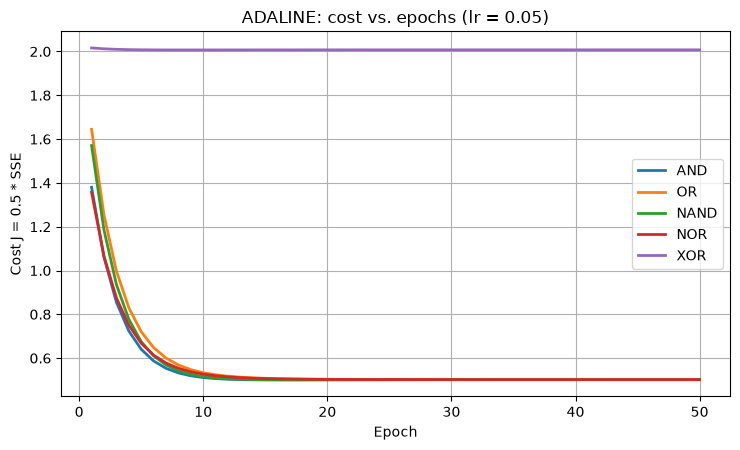

In [3]:
# ---- Task 2: Cost vs. Epochs Plot ----
fig, ax = plt.subplots(figsize=(7.5, 4.6))
for name, c in all_costs.items():
    ax.plot(range(1, len(c) + 1), c, lw=2, label=name)
ax.set_xlabel("Epoch")
ax.set_ylabel("Cost J = 0.5 * SSE")
ax.set_title("ADALINE: cost vs. epochs (lr = 0.05)")
ax.grid(True)
ax.legend()
plt.tight_layout()
plt.show()


Minimum possible cost for AND gate (least-squares): J_min = 0.5000
    lr  cost @ epoch 1   final cost  accuracy behaviour
 0.001          1.8653        1.422      100% slow
 0.010          1.7683        0.522      100% converges
 0.050          1.3798       0.5018      100% converges
 0.200          0.5730        0.551      100% converges
 0.500          1.7614            3       75% UNSTABLE
 0.900          2.5354    3.875e+55       75% DIVERGES


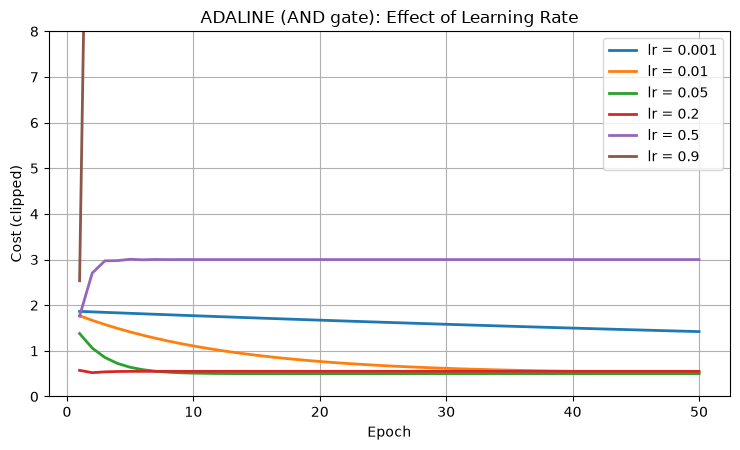

In [4]:
# ---- Task 3: Different Learning Rates on AND Gate ----
Xb = np.hstack([X, np.ones((4, 1))])
J_min = 0.5 * np.sum((gates["AND"] - Xb @ np.linalg.lstsq(Xb, gates["AND"], rcond=None)[0]) ** 2)
print(f"\nMinimum possible cost for AND gate (least-squares): J_min = {J_min:.4f}")
print(f"{'lr':>6s} {'cost @ epoch 1':>15s} {'final cost':>12s} {'accuracy':>9s} behaviour")

fig, ax = plt.subplots(figsize=(7.5, 4.6))
for lr in [0.001, 0.01, 0.05, 0.2, 0.5, 0.9]:
    w, b, c = train_adaline(X, gates["AND"], lr=lr, epochs=50)
    acc = (f(X @ w + b) == gates["AND"]).mean() * 100
    if not np.isfinite(c[-1]) or c[-1] > c[0] * 10:
        behaviour = "DIVERGES"
    elif abs(c[-1] - J_min) < 0.1:
        behaviour = "converges"
    elif c[-1] < 0.9 * c[0]:
        behaviour = "slow"
    else:
        behaviour = "UNSTABLE"
    print(f"{lr:6.3f} {c[0]:15.4f} {c[-1]:12.4g} {acc:8.0f}% {behaviour}")
    ax.plot(range(1, 51), np.clip(c, 0, 20), lw=2, label=f"lr = {lr}")

ax.set_ylim(0, 8)
ax.set_xlabel("Epoch")
ax.set_ylabel("Cost (clipped)")
ax.set_title("ADALINE (AND gate): Effect of Learning Rate")
ax.grid(True)
ax.legend()
plt.tight_layout()
plt.show()